In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("oleksiimartusiuk/e-commerce-data-shein")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'e-commerce-data-shein' dataset.
Path to dataset files: /kaggle/input/e-commerce-data-shein


In [2]:
import os
import glob
import pandas as pd

all_files = glob.glob(
    os.path.join(path, "**", "*"),
    recursive=True
)

all_files = [f for f in all_files if os.path.isfile(f)]

print("Files found:", len(all_files))
for file in all_files:
    print(os.path.basename(file), "->", file)

Files found: 21
us-shein-appliances-3987.csv -> /kaggle/input/e-commerce-data-shein/us-shein-appliances-3987.csv
us-shein-office_and_school_supplies-4233.csv -> /kaggle/input/e-commerce-data-shein/us-shein-office_and_school_supplies-4233.csv
us-shein-underwear_and_sleepwear-4019.csv -> /kaggle/input/e-commerce-data-shein/us-shein-underwear_and_sleepwear-4019.csv
us-shein-mens_clothes-1891.csv -> /kaggle/input/e-commerce-data-shein/us-shein-mens_clothes-1891.csv
us-shein-curve-2849.csv -> /kaggle/input/e-commerce-data-shein/us-shein-curve-2849.csv
us-shein-swimwear-3761.csv -> /kaggle/input/e-commerce-data-shein/us-shein-swimwear-3761.csv
us-shein-womens_clothing-4620.csv -> /kaggle/input/e-commerce-data-shein/us-shein-womens_clothing-4620.csv
us-shein-sports_and_outdoors-3853.csv -> /kaggle/input/e-commerce-data-shein/us-shein-sports_and_outdoors-3853.csv
us-shein-home_textile-3883.csv -> /kaggle/input/e-commerce-data-shein/us-shein-home_textile-3883.csv
us-shein-beauty_and_health-4267

In [3]:

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

if csv_files:
    df = pd.read_csv(csv_files[0])

    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nData types and non-null counts:")
    df.info()
else:
    print("No CSV files found. Check the file listing.")


Dataset shape: (3986, 8)

Column names:
['goods-title-link--jump', 'goods-title-link--jump href', 'rank-title', 'rank-sub', 'price', 'discount', 'selling_proposition', 'goods-title-link']

First 5 rows:


,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,goods-title-link
0,1pc Rechargeable Deep Tissue Muscle Handheld M...,https://us.shein.com/1pc-Rechargeable-Deep-Tis...,#1 Best Sellers,in Give Gifts,$2.03,-22%,NaN,NaN
1,1pc Portable Hanging Neck Fan,https://us.shein.com/1pc-Portable-Hanging-Neck...,#4 Best Sellers,in Top rated in Portable Fans,$6.48,-20%,NaN,NaN
2,1pc Pink Colored Curved Eyelash Curler False E...,https://us.shein.com/1pc-Pink-Colored-Curved-E...,NaN,NaN,$1.80,NaN,400+ sold recently,NaN
3,1 Mini Portable Handheld Fan With 2 Aa Batteri...,https://us.shein.com/1-Mini-Portable-Handheld-...,NaN,NaN,$0.88,-72%,5.6k+ sold recently,NaN
4,"Wit Water Flosser,Portable Oral Irrigator With...",https://us.shein.com/Wit-Water-Flosser-Portabl...,#6 Best Sellers,in Oral Irrigators,$12.06,-40%,NaN,NaN



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   goods-title-link--jump       40 non-null     object
 1   goods-title-link--jump href  40 non-null     object
 2   rank-title                   559 non-null    object
 3   rank-sub                     559 non-null    object
 4   price                        3986 non-null   object
 5   discount                     2459 non-null   object
 6   selling_proposition          1361 non-null   object
 7   goods-title-link             3946 non-null   object
dtypes: object(8)
memory usage: 249.3+ KB


In [4]:
import pandas as pd
import numpy as np

df_raw = df.copy()
df_quality = df_raw.copy()

quality_report = pd.DataFrame({
    "Data_Type" : df_quality.dtypes.astype(str),
    "Non_Null_Count": df_quality.notna().sum(),
    "Missing_Values" : df_quality.isna().sum(),
    "Missing_Percentage": (df_quality.isna().mean() * 100).round(2),
    "Unique_Values" : df_quality.nunique(dropna=True)})

display(quality_report)

,Data_Type,Non_Null_Count,Missing_Values,Missing_Percentage,Unique_Values
goods-title-link--jump,object,40,3946,99.00,40
goods-title-link--jump href,object,40,3946,99.00,40
rank-title,object,559,3427,85.98,10
rank-sub,object,559,3427,85.98,124
price,object,3986,0,0.00,1512
discount,object,2459,1527,38.31,80
selling_proposition,object,1361,2625,65.86,64
goods-title-link,object,3946,40,1.00,3590


In [5]:
print("Total records:", len(df_quality))
print("Exact duplicate rows:", df_quality.duplicated().sum())

Total records: 3986
Exact duplicate rows: 209


In [6]:
for col in df_quality.columns:
    print(f"\n--- {col} ---")
    display(df_quality[col].dropna().head(5))



--- goods-title-link--jump ---


,goods-title-link--jump
0,1pc Rechargeable Deep Tissue Muscle Handheld M...
1,1pc Portable Hanging Neck Fan
2,1pc Pink Colored Curved Eyelash Curler False E...
3,1 Mini Portable Handheld Fan With 2 Aa Batteri...
4,"Wit Water Flosser,Portable Oral Irrigator With..."



--- goods-title-link--jump href ---


,goods-title-link--jump href
0,https://us.shein.com/1pc-Rechargeable-Deep-Tis...
1,https://us.shein.com/1pc-Portable-Hanging-Neck...
2,https://us.shein.com/1pc-Pink-Colored-Curved-E...
3,https://us.shein.com/1-Mini-Portable-Handheld-...
4,https://us.shein.com/Wit-Water-Flosser-Portabl...



--- rank-title ---


...

,discount
0,-22%
1,-20%
3,-72%
4,-40%
8,-41%



--- selling_proposition ---


,selling_proposition
2,400+ sold recently
3,5.6k+ sold recently
11,50+ sold recently
12,30+ sold recently
14,60+ sold recently



--- goods-title-link ---


,goods-title-link
40,4pcs Makeup Sponge Beauty Egg Set - Makeup Spo...
41,1pc Salon Tools Black Pink Universal Silicone ...
42,Portable Lithium Battery Powered Hair Trimmer ...
43,"Multifunctional Manual Food Chopper, Kitchen V..."
44,"1 Set Of 2 Portable Fan Cleaning Brushes, Hous..."


In [7]:
import re

df_clean = df_raw.copy()

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Standardized columns:")
print(df_clean.columns.tolist())

Standardized columns:
['goods_title_link_jump', 'goods_title_link_jump_href', 'rank_title', 'rank_sub', 'price', 'discount', 'selling_proposition', 'goods_title_link']


In [8]:
print("\nSample price values:")
display(df_clean["price"].dropna().sample(
    min(15, df_clean["price"].notna().sum()),
    random_state=42
))

print("\nPrice values with the highest frequency:")
display(df_clean["price"].value_counts().head(15))


Sample price values:


,price
1829,$5.90
2093,$6.50
1513,$3.05
3795,$65.99
1867,$20.98
70,$1.90
1017,$3.10
2883,$45.39
605,$1.90
1226,$15.90



Price values with the highest frequency:


,count
price,
$2.90,35
$38.99,30
$39.99,27
$2.70,26
$22.99,26
$1.90,25
$21.99,23
$23.99,22
$4.00,22


In [9]:
# Convert price from text to numeric
df_clean["price_numeric"] = pd.to_numeric(
    df_clean["price"]
    .astype("string")
    .str.replace(r"[$,\s]", "", regex=True),
    errors="coerce"
)

In [10]:
# Compare original and converted prices
display(df_clean[["price", "price_numeric"]].head(10))

print("Original price data type:", df_clean["price"].dtype)
print("Converted price data type:", df_clean["price_numeric"].dtype)
print("Invalid or missing prices:", df_clean["price_numeric"].isna().sum())

,price,price_numeric
0,$2.03,2.03
1,$6.48,6.48
2,$1.80,1.8
3,$0.88,0.88
4,$12.06,12.06
5,$2.70,2.7
6,$3.50,3.5
7,$4.90,4.9
8,$4.28,4.28
9,$2.76,2.76


Original price data type: object
Converted price data type: Float64
Invalid or missing prices: 0


In [11]:
# Convert discount values such as "-22%" into numeric values such as -22
df_clean["discount_numeric"] = pd.to_numeric(
    df_clean["discount"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Compare original and converted values
display(df_clean[["discount", "discount_numeric"]].head(15))

# Check the results
print("Original discount data type:", df_clean["discount"].dtype)
print("Converted discount data type:", df_clean["discount_numeric"].dtype)
print("Missing or invalid discounts:", df_clean["discount_numeric"].isna().sum())

,discount,discount_numeric
0,-22%,-22
1,-20%,-20
2,NaN,<NA>
3,-72%,-72
4,-40%,-40
5,NaN,<NA>
6,NaN,<NA>
7,NaN,<NA>
8,-41%,-41
9,-5%,-5


Original discount data type: object
Converted discount data type: Int64
Missing or invalid discounts: 1527


In [12]:
df_clean["recent_sales_numeric"] = (
    df_clean["selling_proposition"]
    .str.extract(r"(\d+\.?\d*)")
    .astype(float)
)

display(df_clean[["selling_proposition", "recent_sales_numeric"]].head(10))

,selling_proposition,recent_sales_numeric
0,NaN,NaN
1,NaN,NaN
2,400+ sold recently,400.0
3,5.6k+ sold recently,5.6
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


In [13]:
df_clean["recent_sales_numeric"] = (
    df_clean["selling_proposition"]
    .str.lower()
    .str.extract(r"(\d+\.?\d*)\s*(k)?")
    .apply(lambda x: float(x[0]) * (1000 if x[1] == "k" else 1), axis=1)
)

display(df_clean[["selling_proposition", "recent_sales_numeric"]].head(10))

,selling_proposition,recent_sales_numeric
0,NaN,NaN
1,NaN,NaN
2,400+ sold recently,400.0
3,5.6k+ sold recently,5600.0
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


In [14]:
print("Total rows:", len(df_clean))

print("Duplicate rows:", df_clean.duplicated().sum())

print("Duplicate product URLs:",
      df_clean["goods_title_link_jump_href"].duplicated().sum())

Total rows: 3986
Duplicate rows: 209
Duplicate product URLs: 3945


In [15]:
print("Missing product URLs:",
      df_clean["goods_title_link_jump_href"].isna().sum())

print("Non-missing product URLs:",
      df_clean["goods_title_link_jump_href"].notna().sum())

print("Unique product URLs:",
      df_clean["goods_title_link_jump_href"].nunique())

Missing product URLs: 3946
Non-missing product URLs: 40
Unique product URLs: 40


In [16]:
# Count duplicate URLs only where the URL exists
valid_urls = df_clean["goods_title_link_jump_href"].dropna()

print("Duplicate non-missing URLs:", valid_urls.duplicated().sum())

# Check duplicate rows
print("Duplicate complete rows:", df_clean.duplicated().sum())

Duplicate non-missing URLs: 0
Duplicate complete rows: 209


In [17]:
df_deduplicated = df_clean.drop_duplicates().copy()

print("Rows before:", len(df_clean))
print("Rows after:", len(df_deduplicated))
print("Rows removed:", len(df_clean) - len(df_deduplicated))

Rows before: 3986
Rows after: 3777
Rows removed: 209


In [18]:
missing = df_deduplicated.isnull().sum()

print("Missing values in each column:")
display(missing.to_frame(name="Missing_Count"))

Missing values in each column:


,Missing_Count
goods_title_link_jump,3737
goods_title_link_jump_href,3737
rank_title,3218
rank_sub,3218
price,0
discount,1518
selling_proposition,2425
goods_title_link,40
price_numeric,0
discount_numeric,1518


In [19]:
print("Missing values in each product title column:")

print("goods_title_link_jump:",
      df_deduplicated["goods_title_link_jump"].isna().sum())

print("goods_title_link:",
      df_deduplicated["goods_title_link"].isna().sum())

# Display examples from the more complete title column
display(df_deduplicated[["goods_title_link"]].head(10))

Missing values in each product title column:
goods_title_link_jump: 3737
goods_title_link: 40


,goods_title_link
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN


In [20]:
df_deduplicated["product_name"] = (
    df_deduplicated["goods_title_link"]
    .fillna(df_deduplicated["goods_title_link_jump"])
)

print("Missing product names:", df_deduplicated["product_name"].isna().sum())

display(df_deduplicated[["product_name", "price"]].head(15))

Missing product names: 0


,product_name,price
0,1pc Rechargeable Deep Tissue Muscle Handheld M...,$2.03
1,1pc Portable Hanging Neck Fan,$6.48
2,1pc Pink Colored Curved Eyelash Curler False E...,$1.80
3,1 Mini Portable Handheld Fan With 2 Aa Batteri...,$0.88
4,"Wit Water Flosser,Portable Oral Irrigator With...",$12.06
5,"1pc Ice Pop Mold, Plastic Ice Cream Mold, Froz...",$2.70
6,"Mini Pocket Bluetooth Thermal Printer, Portabl...",$3.50
7,1 PC 400ML Classic Ultra-Silent Air Humidifier...,$4.90
8,6 Modes Multi-Functional Sonic Electric Toothb...,$4.28
9,1pc AA Battery Operated Portable Handheld Mini...,$2.76


In [21]:
print("Zero or negative prices:",
      (df_deduplicated["price_numeric"] <= 0).sum())

print("Minimum price:", df_deduplicated["price_numeric"].min())
print("Maximum price:", df_deduplicated["price_numeric"].max())

display(
    df_deduplicated[
        df_deduplicated["price_numeric"] <= 0
    ][["product_name", "price", "price_numeric"]].head(10)
)

Zero or negative prices: 0
Minimum price: 0.5
Maximum price: 2399.99


,product_name,price,price_numeric


In [22]:
high_price = df_deduplicated[
    df_deduplicated["price_numeric"] > 500
]

print("Products priced above $500:", len(high_price))

display(
    high_price[["product_name", "price", "price_numeric"]]
)

Products priced above $500: 26


,product_name,price,price_numeric
1441,"VEVOR Slushy Machine, 30L Slushie Machine For ...","$1,430.99",1430.99
1959,"VEVOR Commercial Meatball Forming Machine, 280...","$1,077.99",1077.99
2337,Smeg Smeg | Espresso Machine,$683.40,683.4
2342,Breville Breville | Bambino Plus ThermoJet Esp...,$638.36,638.36
2465,VEVOR Commercial Slushy Machine 15Lx2 Tank Mar...,$714.66,714.66
2469,VEVOR Commercial Slushy Machine 3LX2 Tank Slus...,$572.53,572.53
2537,VEVOR Commercial Electric Meat Bandsaw 2200W S...,$725.75,725.75
2796,"Massage Chair Recliner With Zero Gravity, Full...",$584.64,584.64
2849,"VEVOR Commercial Ice Cream Machine, 20-25L/H Y...","$2,254.99",2254.99
2976,BOSSCARE Full Body Airbag Massage Chair Reclin...,$839.99,839.99


In [23]:
df_deduplicated["high_price_flag"] = (
    df_deduplicated["price_numeric"] > 500
)

print("High-price products:",
      df_deduplicated["high_price_flag"].sum())

print("Normal-price products:",
      (~df_deduplicated["high_price_flag"]).sum())

High-price products: 26
Normal-price products: 3751


In [24]:
print("Minimum discount:", df_deduplicated["discount_numeric"].min())
print("Maximum discount:", df_deduplicated["discount_numeric"].max())

print("Discounts below -100%:",
      (df_deduplicated["discount_numeric"] < -100).sum())

print("Discounts above 0%:",
      (df_deduplicated["discount_numeric"] > 0).sum())

Minimum discount: -88
Maximum discount: -1
Discounts below -100%: 0
Discounts above 0%: 0


In [25]:
missing_discount = df_deduplicated["discount_numeric"].isna().sum()

print("Missing discounts:", missing_discount)
print(
    "Missing discount percentage:",
    round(missing_discount / len(df_deduplicated) * 100, 2),
    "%"
)

Missing discounts: 1518
Missing discount percentage: 40.19 %


In [26]:
missing_sales = df_deduplicated["recent_sales_numeric"].isna().sum()

print("Missing sales values:", missing_sales)

print(
    "Missing sales percentage:",
    round(missing_sales / len(df_deduplicated) * 100, 2),
    "%"
)

Missing sales values: 2425
Missing sales percentage: 64.2 %


In [27]:
quality_summary = pd.DataFrame({
    "Check": [
        "Total records after deduplication",
        "Missing product names",
        "Missing prices",
        "Zero or negative prices",
        "High-price products (over $500)",
        "Missing discounts",
        "Missing recent-sales values"
    ],
    "Result": [
        len(df_deduplicated),
        df_deduplicated["product_name"].isna().sum(),
        df_deduplicated["price_numeric"].isna().sum(),
        (df_deduplicated["price_numeric"] <= 0).sum(),
        df_deduplicated["high_price_flag"].sum(),
        df_deduplicated["discount_numeric"].isna().sum(),
        df_deduplicated["recent_sales_numeric"].isna().sum()
    ]
})

display(quality_summary)

,Check,Result
0,Total records after deduplication,3777
1,Missing product names,0
2,Missing prices,0
3,Zero or negative prices,0
4,High-price products (over $500),26
5,Missing discounts,1518
6,Missing recent-sales values,2425


In [28]:
print("Average price: $", round(df_deduplicated["price_numeric"].mean(), 2))
print("Median price: $", round(df_deduplicated["price_numeric"].median(), 2))
print("Lowest price: $", round(df_deduplicated["price_numeric"].min(), 2))
print("Highest price: $", round(df_deduplicated["price_numeric"].max(), 2))
print("Number of products:", df_deduplicated["product_name"].nunique())

Average price: $ 41.17
Median price: $ 16.1
Lowest price: $ 0.5
Highest price: $ 2399.99
Number of products: 3627


In [29]:
df_deduplicated["price_category"] = pd.cut(
    df_deduplicated["price_numeric"],
    bins=[0, 10, 25, 100, 500, float("inf")],
    labels=["Under $10", "$10–25", "$25–100", "$100–500", "Over $500"]
)

display(
    df_deduplicated["price_category"]
    .value_counts()
    .sort_index()
    .to_frame(name="Product_Count")
)

,Product_Count
price_category,
Under $10,1391
$10–25,990
$25–100,1059
$100–500,311
Over $500,26


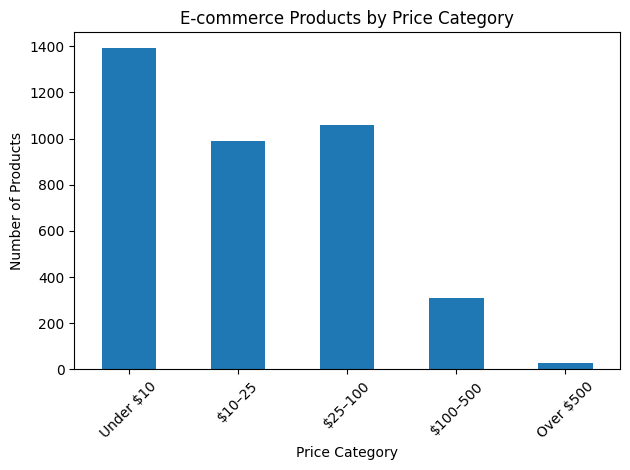

In [30]:
import matplotlib.pyplot as plt

price_counts = df_deduplicated["price_category"].value_counts().sort_index()

price_counts.plot(kind="bar")

plt.title("E-commerce Products by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
discount_analysis = (
    df_deduplicated
    .groupby("price_category", observed=False)["discount_numeric"]
    .agg(["mean", "count"])
    .round(2)
)

discount_analysis.columns = ["Average_Discount_Percent", "Products_With_Discount"]

display(discount_analysis)

,Average_Discount_Percent,Products_With_Discount
price_category,,
Under $10,-23.39,658
$10–25,-28.65,549
$25–100,-33.64,746
$100–500,-28.42,286
Over $500,-38.8,20


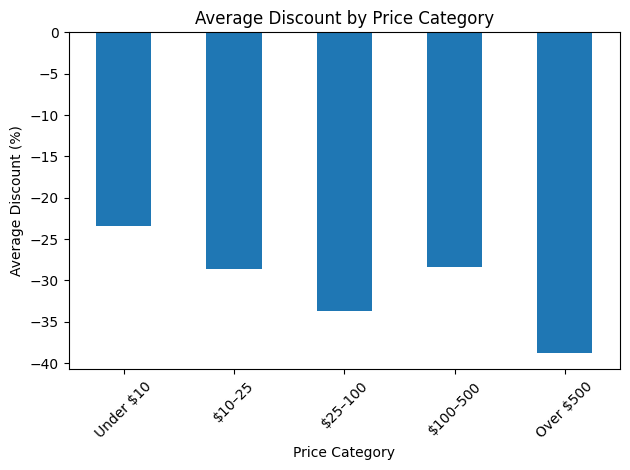

In [32]:
discount_analysis["Average_Discount_Percent"].plot(kind="bar")

plt.title("Average Discount by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
sales_analysis = (
    df_deduplicated
    .groupby("price_category", observed=False)["recent_sales_numeric"]
    .agg(["mean", "count"])
    .round(2)
)

sales_analysis.columns = [
    "Average_Recent_Sales",
    "Products_With_Sales_Data"
]

display(sales_analysis)

,Average_Recent_Sales,Products_With_Sales_Data
price_category,,
Under $10,452.46,788
$10–25,200.77,389
$25–100,67.87,155
$100–500,26.11,18
Over $500,10.00,2


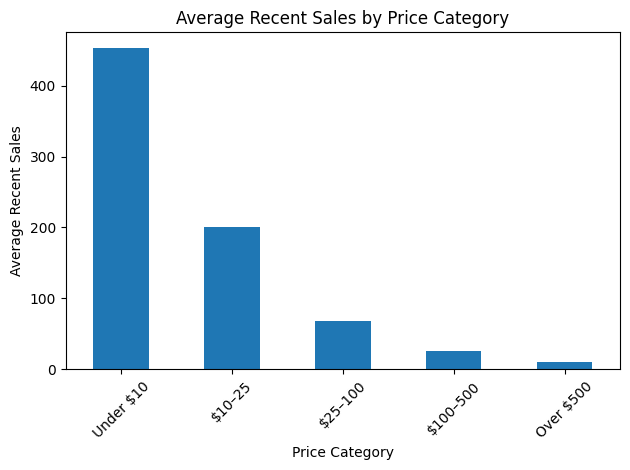

In [34]:
sales_analysis["Average_Recent_Sales"].plot(kind="bar")

plt.title("Average Recent Sales by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Average Recent Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
checks = {
    "Product names missing": df_deduplicated["product_name"].isna().sum(),
    "Prices missing": df_deduplicated["price_numeric"].isna().sum(),
    "Invalid prices": (df_deduplicated["price_numeric"] <= 0).sum(),
    "Discounts below -100%": (df_deduplicated["discount_numeric"] < -100).sum(),
    "Discounts above 0%": (df_deduplicated["discount_numeric"] > 0).sum()
}

for check, errors in checks.items():
    status = "PASS" if errors == 0 else "FAIL"
    print(f"{check}: {status} ({errors} errors)")

Product names missing: PASS (0 errors)
Prices missing: PASS (0 errors)
Invalid prices: PASS (0 errors)
Discounts below -100%: PASS (0 errors)
Discounts above 0%: PASS (0 errors)


In [36]:
df_deduplicated.to_csv(
    "ecommerce_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [37]:
quality_report = pd.DataFrame({
    "Check": list(checks.keys()),
    "Errors": list(checks.values())
})

quality_report["Status"] = quality_report["Errors"].apply(
    lambda x: "PASS" if x == 0 else "FAIL"
)

quality_report.to_csv("ecommerce_quality_report.csv", index=False)

display(quality_report)

print("Quality report saved successfully!")

,Check,Errors,Status
0,Product names missing,0,PASS
1,Prices missing,0,PASS
2,Invalid prices,0,PASS
3,Discounts below -100%,0,PASS
4,Discounts above 0%,0,PASS


Quality report saved successfully!


In [38]:
project_summary = {
    "Metric": [
        "Original records",
        "Records after removing exact duplicates",
        "Duplicate rows removed",
        "Missing product names",
        "Missing or invalid prices",
        "Products priced above $500",
        "Missing discounts",
        "Missing recent-sales values",
        "Unique product names",
        "Average product price",
        "Median product price",
        "Automated checks passed"
    ],
    "Result": [
        len(df_raw),
        len(df_deduplicated),
        len(df_raw) - len(df_deduplicated),
        df_deduplicated["product_name"].isna().sum(),
        df_deduplicated["price_numeric"].isna().sum()
            + (df_deduplicated["price_numeric"] <= 0).sum(),
        int(df_deduplicated["high_price_flag"].sum()),
        df_deduplicated["discount_numeric"].isna().sum(),
        df_deduplicated["recent_sales_numeric"].isna().sum(),
        df_deduplicated["product_name"].nunique(),
        round(df_deduplicated["price_numeric"].mean(), 2),
        round(df_deduplicated["price_numeric"].median(), 2),
        sum(value == 0 for value in checks.values())
    ]
}

project_summary = pd.DataFrame(project_summary)

display(project_summary)

project_summary.to_csv("ecommerce_project_summary.csv", index=False)

print("Project summary saved successfully!")

,Metric,Result
0,Original records,3986.00
1,Records after removing exact duplicates,3777.00
2,Duplicate rows removed,209.00
3,Missing product names,0.00
4,Missing or invalid prices,0.00
5,Products priced above $500,26.00
6,Missing discounts,1518.00
7,Missing recent-sales values,2425.00
8,Unique product names,3627.00
9,Average product price,41.17


Project summary saved successfully!
